# Challenge "Operazione Nebbia" · Kit della squadra
**AI 4 Security · Parte 2** — Versione studente

Avete 14 giorni di dati storici di un'azienda con 8 server. Dovete costruire **due modelli** che la proteggano.
Alla fine della sessione il docente importerà i vostri modelli e li metterà alla prova su un **incidente di 48 ore che nessuno ha visto**.

| Modello | Cosa fa | Vincolo |
|---|---|---|
| **1 · Detector di anomalie** | dalla telemetria CPU/RAM produce un punteggio per ogni minuto e host, più una soglia | al massimo **30 allarmi al giorno** |
| **2 · Piano di patch** | dal report dello scanner produce le azioni di remediation in ordine di priorità | **20 ore di lavoro** nella settimana prima dell'incidente |

**Come si vince**

| Cosa succede nell'incidente | Punti |
|---|---|
| La vulnerabilità d'ingresso rientrava nelle 20 ore di patch: **attacco prevenuto** | 40 |
| Miner rilevato entro 15 minuti (entro 2 ore: 10) | 20 |
| Beaconing rilevato entro 15 minuti (entro 2 ore: 10) | 20 |
| Nessun allarme sul deploy legittimo | 10 |
| Nota chiara sulla scelta di soglia e priorità | 10 |

Se il piano di patch previene l'attacco, i punti di miner e beaconing sono assegnati comunque.

**Regole degli allarmi (le stesse del docente):** minuti consecutivi sopra soglia sullo stesso host, con pause fino a 5 minuti, formano **un solo allarme**.
Ogni giorno gli analisti guardano i **primi 30 allarmi in ordine di arrivo**: gli altri restano in coda e non contano.

**Consegna:** un file `consegna_<squadra>.pkl` generato dalla sezione 5 di questo notebook.

## 0 · Preparazione

In [195]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloudpickle
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression

plt.rcParams["figure.figsize"] = (11, 3.5)
print("Ambiente pronto")

Ambiente pronto


In [196]:
# @title Generazione del kit e regole di valutazione (eseguire senza modificare)
import numpy as np
import pandas as pd

HOST = ["web-01", "web-02", "app-01", "app-02", "db-01", "bastion-01", "test-01", "mon-01"]
# CPU notturna di base e ampiezza del carico diurno per host
PROFILO = {"web-01": (12, 40), "web-02": (14, 32), "app-01": (18, 35), "app-02": (17, 35),
           "db-01": (20, 30), "bastion-01": (8, 10), "test-01": (10, 15), "mon-01": (15, 8)}
RAM = {"web-01": 48, "web-02": 45, "app-01": 60, "app-02": 58, "db-01": 70, "bastion-01": 30, "test-01": 40, "mon-01": 50}
INIZIO_KIT = pd.Timestamp("2025-05-19 00:00")      # lunedì
GIORNI_KIT = 14
INIZIO_INC = pd.Timestamp("2025-06-02 00:00")      # lunedì successivo
GIORNI_INC = 2


def _carico_diurno(ts):
    """Curva 0-1 del carico lavorativo: sale dalle 8, massimo a metà giornata, scende dopo le 19; ridotto nel weekend."""
    ore = ts.hour + ts.minute / 60
    c = np.clip(np.sin(np.pi * (ore - 7.5) / 12), 0, None) ** 1.5
    return np.where(ts.dayofweek >= 5, 0.35 * c, c)


def _telemetria_base(inizio, giorni, rng):
    ts = pd.date_range(inizio, periods=giorni * 1440, freq="min")
    righe = []
    for h in HOST:
        notte, amp = PROFILO[h]
        cpu = notte + amp * _carico_diurno(ts) + rng.normal(0, 3, len(ts))
        ram = RAM[h] + 5 * _carico_diurno(ts) + rng.normal(0, 1.5, len(ts))
        d = pd.DataFrame({"timestamp": ts, "host": h, "cpu_pct": cpu, "ram_pct": ram})
        righe.append(d)
    df = pd.concat(righe, ignore_index=True)
    # attività legittime ricorrenti
    m = df["timestamp"].dt.hour * 60 + df["timestamp"].dt.minute
    backup = (m >= 120) & (m < 135)
    df.loc[backup, "cpu_pct"] += 20
    deploy = df["host"].isin(["app-01", "app-02"]) & (df["timestamp"].dt.dayofweek < 5) & (m >= 600) & (m < 620)
    df.loc[deploy, "cpu_pct"] += 35
    return df


def _applica(df, host, inizio, fine, delta_cpu=0.0, fisso=None, rng=None):
    k = (df["host"] == host) & (df["timestamp"] >= inizio) & (df["timestamp"] < fine)
    if fisso is not None:
        df.loc[k, "cpu_pct"] = fisso + rng.normal(0, 2, k.sum())
    else:
        df.loc[k, "cpu_pct"] += delta_cpu
    return k


def _beaconing(df, host, inizio, fine, periodo, jitter, ampiezza, rng):
    t = inizio
    minuti = []
    while t < fine:
        k = _applica(df, host, t, t + pd.Timedelta(minutes=2), delta_cpu=ampiezza)
        minuti.append(t)
        passo = periodo * (1 + rng.uniform(-jitter, jitter))
        t = t + pd.Timedelta(minutes=round(passo))
    return minuti


def _chiudi(df):
    df["cpu_pct"] = df["cpu_pct"].clip(0, 100).round(1)
    df["ram_pct"] = df["ram_pct"].clip(0, 100).round(1)
    return df


# ------------------------------------------------------------------ inventario e vulnerabilità
INVENTARIO = pd.DataFrame([
    ("web-01", "portale clienti (CMS)", 2, True), ("web-02", "sito interno", 1, False),
    ("app-01", "backend ordini", 3, False), ("app-02", "backend ordini", 3, False),
    ("db-01", "database clienti", 3, False), ("bastion-01", "accesso amministrativo", 3, False),
    ("test-01", "ambiente di test", 1, False), ("mon-01", "monitoraggio", 1, False),
], columns=["asset", "ruolo", "criticita", "esposto_internet"])

# azione: (ore di lavoro, [(vuln_id, cvss, epss, [asset...])])
# CVE-2021-44228 è reale (Log4Shell); gli ID "SIM-" sono sintetici; gli EPSS sono valori di esempio.
AZIONI = {
    "UPGRADE · log4j-core · 2.17.1": (6, [("CVE-2021-44228", 10.0, 0.94, ["app-01", "app-02"])]),
    "UPGRADE · openssh · 9.6p1": (3, [("SIM-2023-0301", 5.9, 0.45, ["bastion-01", "db-01"])]),
    "UPGRADE · kernel · 6.1.70": (6, [("SIM-2023-0601", 7.8, 0.20, ["db-01", "bastion-01", "app-01"])]),
    "UPGRADE · tomcat · 9.0.83": (4, [("SIM-2023-0701", 7.5, 0.25, ["app-01", "app-02"])]),
    "UPGRADE · postgresql · 15.6": (5, [("SIM-2024-0901", 8.8, 0.15, ["db-01"])]),
    "UPGRADE · openssl · 3.0.7": (4, [("CVE-2022-3602", 7.5, 0.06, ["web-02", "app-01", "test-01"])]),
    "UPGRADE · webapp-cms · 4.2.9": (3, [("SIM-2024-1101", 6.5, 0.07, ["web-01"])]),
    "UPGRADE · grafana · 10.2.3": (2, [("SIM-2024-1201", 6.1, 0.05, ["mon-01"])]),
    "UPGRADE · nginx · 1.24.0": (3, [("SIM-2023-0201", 5.3, 0.02, ["web-01", "web-02"])]),
    "UPGRADE · jquery · 3.5.0": (2, [("SIM-2020-0501", 6.1, 0.01, ["web-01", "web-02"])]),
}
BUDGET_ORE = 20
BUDGET_ALLARMI = 30


def report_scanner():
    righe = []
    for az, (ore, vulns) in AZIONI.items():
        for vid, cvss, epss, assets in vulns:
            for a in assets:
                righe.append((a, vid, cvss, epss, az, ore))
    r = pd.DataFrame(righe, columns=["asset", "vuln_id", "cvss", "epss", "azione", "ore_azione"])
    r.insert(0, "finding_id", [f"F{i:03d}" for i in range(len(r))])
    return r


def storico_vulnerabilita(n=800, seed=5):
    """Dodici mesi di finding passati, con l'esito: la vulnerabilità è stata sfruttata?"""
    rng = np.random.default_rng(seed)
    cvss = np.clip(rng.normal(6.8, 1.6, n), 2, 10).round(1)
    epss = np.clip(rng.beta(0.6, 5, n), 0.001, 0.98).round(3)
    crit = rng.choice([1, 2, 3], n, p=[0.35, 0.35, 0.3])
    esposto = rng.random(n) < 0.18
    logit = -4.3 + 3.0 * esposto + 5.0 * epss + 0.15 * (cvss - 6)
    sfruttata = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return pd.DataFrame({"cvss": cvss, "epss": epss, "criticita": crit, "esposto_internet": esposto,
                         "sfruttata": sfruttata})


# ------------------------------------------------------------------ kit e incidente
def genera_kit(seed=2025):
    rng = np.random.default_rng(seed)
    df = _telemetria_base(INIZIO_KIT, GIORNI_KIT, rng)
    g = lambda d, hh, mm=0: INIZIO_KIT + pd.Timedelta(days=d, hours=hh, minutes=mm)
    episodi = []
    for host, d, h0, durata in [("app-02", 2, 14, 150), ("web-02", 6, 11, 90), ("db-01", 10, 15, 120)]:
        _applica(df, host, g(d, h0), g(d, h0) + pd.Timedelta(minutes=durata), fisso=95, rng=rng)
        episodi.append((host, g(d, h0), g(d, h0) + pd.Timedelta(minutes=durata), "miner",
                       "CPU al 95% di giorno, rilevato dal SOC in pochi minuti"))
    # l'episodio che fa da indizio: miner notturno a metà potenza, scoperto tardi
    _applica(df, "test-01", g(8, 2, 30), g(8, 5, 0), delta_cpu=30)
    episodi.append(("test-01", g(8, 2, 30), g(8, 5, 0), "miner",
                    "CPU intorno al 40% di notte; nessun allarme, scoperto 3 giorni dopo da un controllo manuale"))
    for host, d, h0, h1 in [("mon-01", 4, 14, 18), ("web-02", 12, 9, 13)]:
        _beaconing(df, host, g(d, h0), g(d, h1), periodo=15, jitter=0.0, ampiezza=25, rng=rng)
        episodi.append((host, g(d, h0), g(d, h1), "beaconing", "picchi di CPU ogni 15 minuti esatti verso un IP esterno"))
    storico = pd.DataFrame(episodi, columns=["host", "inizio", "fine", "tipo", "note"])
    return _chiudi(df), storico



# --- (usate anche per l'autoverifica)
def allarmi_visti(df, punteggi, soglia, budget=BUDGET_ALLARMI, pausa=5):
    """Minuti sopra soglia -> allarmi (minuti consecutivi dello stesso host, con pause fino a `pausa` minuti,
    formano un solo allarme). Ogni giorno gli analisti guardano i primi `budget` allarmi in ordine di arrivo."""
    d = df[["timestamp", "host"]].copy()
    d["sopra"] = np.asarray(punteggi) >= soglia
    d = d[d["sopra"]].sort_values(["host", "timestamp"])
    if d.empty:
        return d.assign(allarme=pd.Series(dtype=int), visto=pd.Series(dtype=bool)), pd.DataFrame()
    nuovo = (d["host"] != d["host"].shift()) | (d["timestamp"].diff() > pd.Timedelta(minutes=pausa))
    d["allarme"] = nuovo.cumsum()
    al = d.groupby("allarme").agg(host=("host", "first"), inizio=("timestamp", "min"), fine=("timestamp", "max"),
                                  minuti=("timestamp", "size")).reset_index()
    al["giorno"] = al["inizio"].dt.date
    al = al.sort_values("inizio")
    al["posizione_coda"] = al.groupby("giorno").cumcount() + 1
    al["visto"] = al["posizione_coda"] <= budget
    d = d.merge(al[["allarme", "visto"]], on="allarme")
    return d, al


def primo_rilevamento(minuti_visti, host, inizio, fine, escludi=None):
    """Primo minuto visto sull'host dentro [inizio, fine), escludendo eventuali minuti; restituisce il ritardo in minuti."""
    m = minuti_visti[(minuti_visti["host"] == host) & (minuti_visti["timestamp"] >= inizio) &
                     (minuti_visti["timestamp"] < fine) & minuti_visti["visto"]]
    if escludi is not None:
        m = m[~m["timestamp"].isin(escludi)]
    if m.empty:
        return None
    return (m["timestamp"].min() - inizio).total_seconds() / 60

print('Kit pronto')

Kit pronto


---
## 1 · I dati del kit

- `telemetria`: CPU e RAM al minuto, 8 server, 14 giorni.
- `storico`: gli **episodi passati** noti al SOC, con le note degli analisti. Leggetele con attenzione.
- `INVENTARIO`: criticità degli asset ed esposizione su internet.
- `report`: le vulnerabilità aperte oggi, con CVSS, EPSS, azione di remediation e ore di lavoro per azione.
- `storico_vuln`: 12 mesi di vulnerabilità passate, con l'esito: **è stata sfruttata?**

In [197]:
telemetria, storico = genera_kit()
report = report_scanner()
storico_vuln = storico_vulnerabilita()
print("Telemetria:", telemetria.shape, "dal", telemetria["timestamp"].min(), "al", telemetria["timestamp"].max())
storico

Telemetria: (161280, 4) dal 2025-05-19 00:00:00 al 2025-06-01 23:59:00


,host,inizio,fine,tipo,note
0,app-02,2025-05-21 14:00:00,2025-05-21 16:30:00,miner,"CPU al 95% di giorno, rilevato dal SOC in poch..."
1,web-02,2025-05-25 11:00:00,2025-05-25 12:30:00,miner,"CPU al 95% di giorno, rilevato dal SOC in poch..."
2,db-01,2025-05-29 15:00:00,2025-05-29 17:00:00,miner,"CPU al 95% di giorno, rilevato dal SOC in poch..."
3,test-01,2025-05-27 02:30:00,2025-05-27 05:00:00,miner,"CPU intorno al 40% di notte; nessun allarme, s..."
4,mon-01,2025-05-23 14:00:00,2025-05-23 18:00:00,beaconing,picchi di CPU ogni 15 minuti esatti verso un I...
5,web-02,2025-05-31 09:00:00,2025-05-31 13:00:00,beaconing,picchi di CPU ogni 15 minuti esatti verso un I...


In [198]:
display(INVENTARIO)
report.head(12)

,asset,ruolo,criticita,esposto_internet
0,web-01,portale clienti (CMS),2,True
1,web-02,sito interno,1,False
2,app-01,backend ordini,3,False
3,app-02,backend ordini,3,False
4,db-01,database clienti,3,False
5,bastion-01,accesso amministrativo,3,False
6,test-01,ambiente di test,1,False
7,mon-01,monitoraggio,1,False


,finding_id,asset,vuln_id,cvss,epss,azione,ore_azione
0,F000,app-01,CVE-2021-44228,10.0,0.94,UPGRADE · log4j-core · 2.17.1,6
1,F001,app-02,CVE-2021-44228,10.0,0.94,UPGRADE · log4j-core · 2.17.1,6
2,F002,bastion-01,SIM-2023-0301,5.9,0.45,UPGRADE · openssh · 9.6p1,3
3,F003,db-01,SIM-2023-0301,5.9,0.45,UPGRADE · openssh · 9.6p1,3
4,F004,db-01,SIM-2023-0601,7.8,0.20,UPGRADE · kernel · 6.1.70,6
5,F005,bastion-01,SIM-2023-0601,7.8,0.20,UPGRADE · kernel · 6.1.70,6
6,F006,app-01,SIM-2023-0601,7.8,0.20,UPGRADE · kernel · 6.1.70,6
7,F007,app-01,SIM-2023-0701,7.5,0.25,UPGRADE · tomcat · 9.0.83,4
8,F008,app-02,SIM-2023-0701,7.5,0.25,UPGRADE · tomcat · 9.0.83,4
9,F009,db-01,SIM-2024-0901,8.8,0.15,UPGRADE · postgresql · 15.6,5


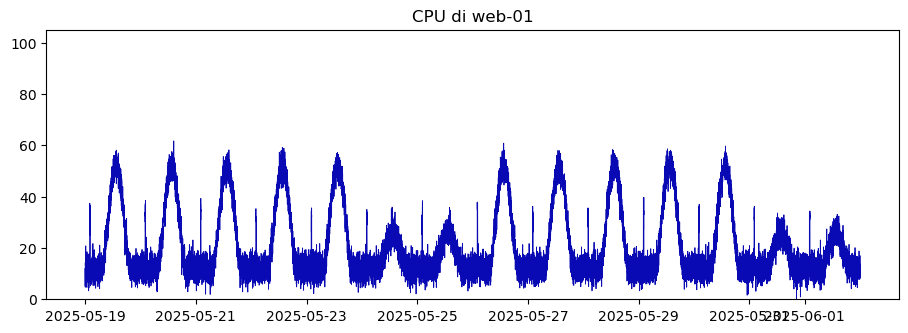

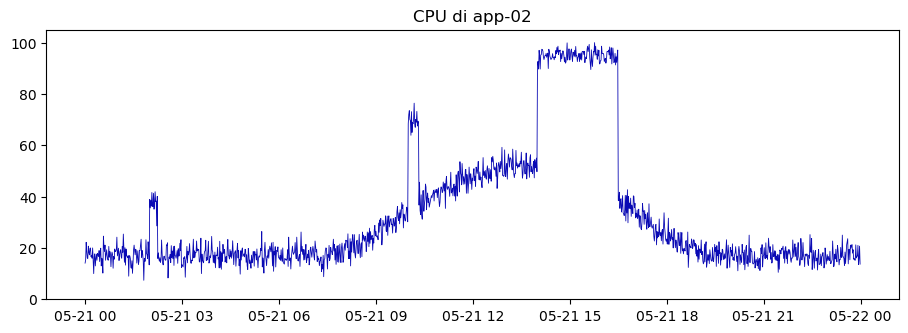

In [199]:
def mostra(host, giorno=None):
    d = telemetria[telemetria["host"] == host]
    if giorno is not None:
        d = d[d["timestamp"].dt.date == pd.Timestamp(giorno).date()]
    plt.plot(d["timestamp"], d["cpu_pct"], lw=0.6, color="#0A0AB4")
    plt.title(f"CPU di {host}"); plt.ylim(0, 105); plt.show()

mostra("web-01")                      # una settimana tipica del server esposto
mostra("app-02", "2025-05-21")        # un episodio passato di miner

**Esplorate liberamente:** gli altri episodi dello storico, le differenze fra giorno e notte, fra feriali e weekend, i deploy delle 10:00.

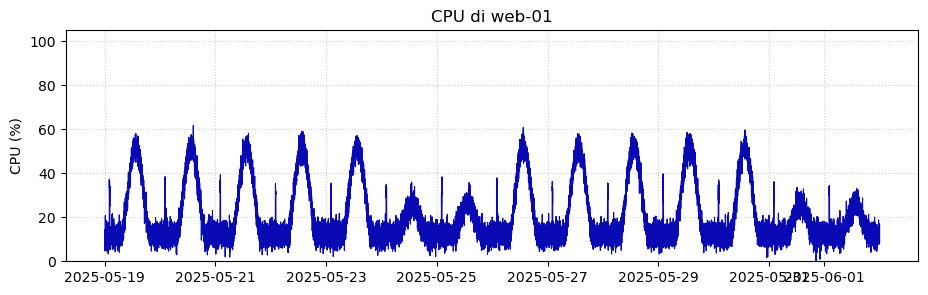

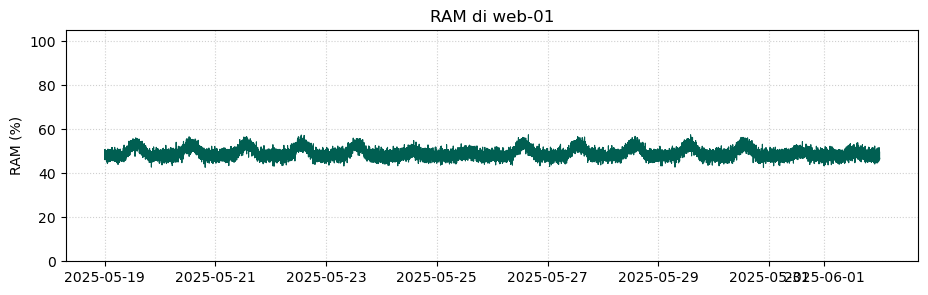

In [200]:
def mostra_host(h, evidenzia=None):
    d = telemetria.loc[telemetria["host"] == h]

    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(d["timestamp"], d["cpu_pct"], color="#0A0AB4", lw=0.8)
    ax.set_title(f"CPU di {h}")
    ax.set_ylabel("CPU (%)")
    ax.set_ylim(0, 105)
    ax.grid(True, linestyle=":", alpha=0.6)

    if evidenzia is not None:
        punti = d.loc[evidenzia.reindex(d.index, fill_value=False)]
        ax.scatter(punti["timestamp"], punti["cpu_pct"], color="#E3002B", s=8, label="anomalia")
        ax.legend(loc="upper right")

    plt.show()

    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(d["timestamp"], d["ram_pct"], color="#005F52", lw=0.8)
    ax.set_title(f"RAM di {h}")
    ax.set_ylabel("RAM (%)")
    ax.set_ylim(0, 105)
    ax.grid(True, linestyle=":", alpha=0.6)
    plt.show()


mostra_host("web-01")

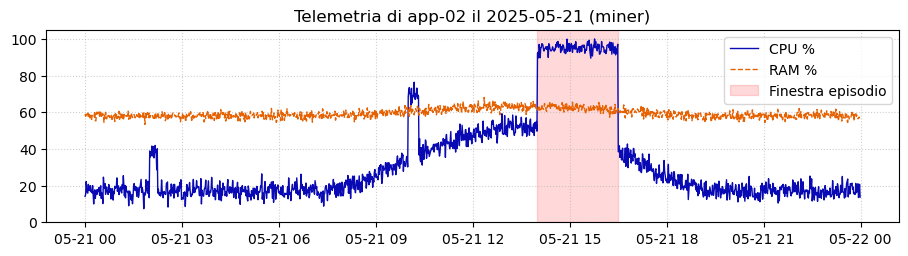

CPU al 95% di giorno, rilevato dal SOC in pochi minuti
--------------------------------------------------------------------------------


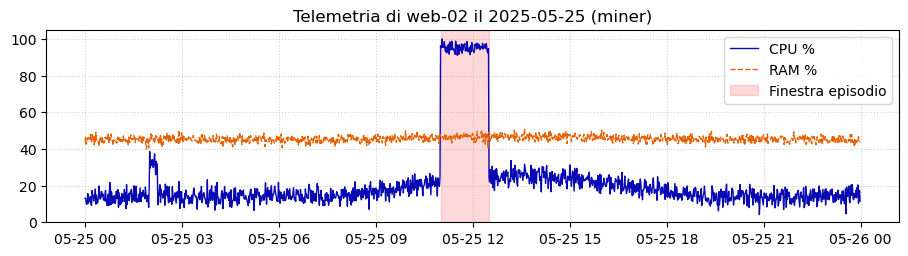

CPU al 95% di giorno, rilevato dal SOC in pochi minuti
--------------------------------------------------------------------------------


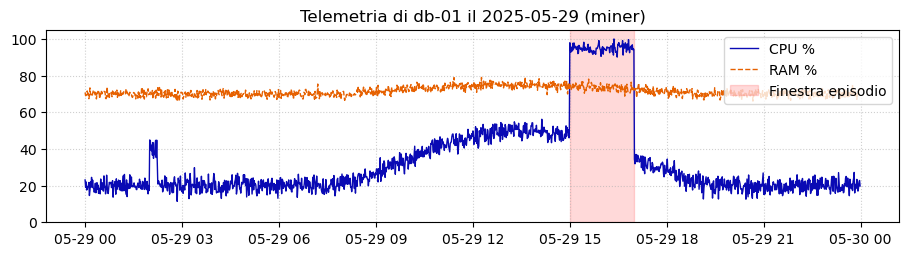

CPU al 95% di giorno, rilevato dal SOC in pochi minuti
--------------------------------------------------------------------------------


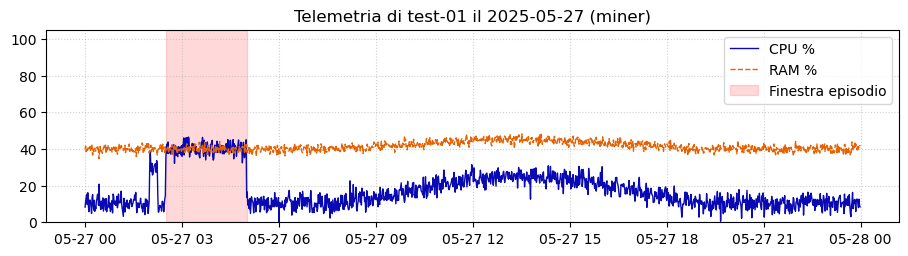

CPU intorno al 40% di notte; nessun allarme, scoperto 3 giorni dopo da un controllo manuale
--------------------------------------------------------------------------------


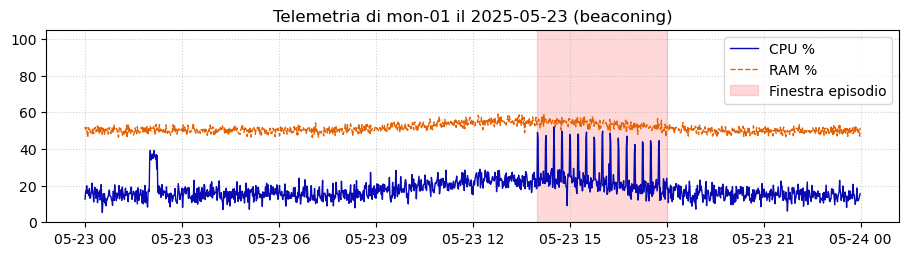

picchi di CPU ogni 15 minuti esatti verso un IP esterno
--------------------------------------------------------------------------------


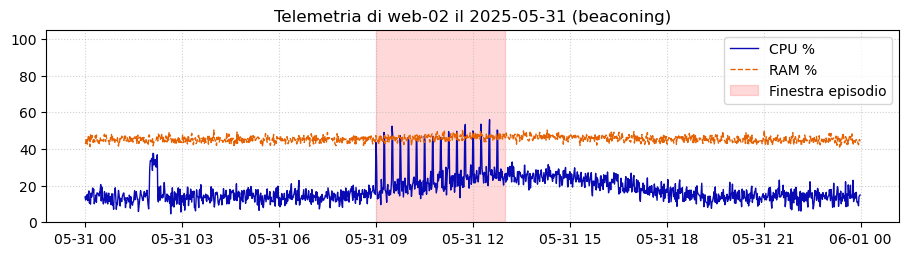

picchi di CPU ogni 15 minuti esatti verso un IP esterno
--------------------------------------------------------------------------------
CPU e RAM per fascia oraria:


cpu_pct        ram_pct       
          mean median    mean median
fascia                              
giorno    26.3   22.6    52.4   51.3
notte     14.7   14.6    50.1   49.0

CPU e RAM per tipo di giorno:


cpu_pct        ram_pct       
               mean median    mean median
tipo_giorno                              
feriale        21.9   17.9    51.5   50.4
weekend        17.1   16.3    50.6   49.5

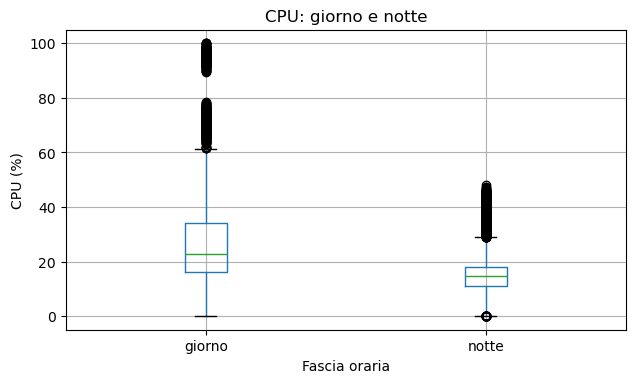

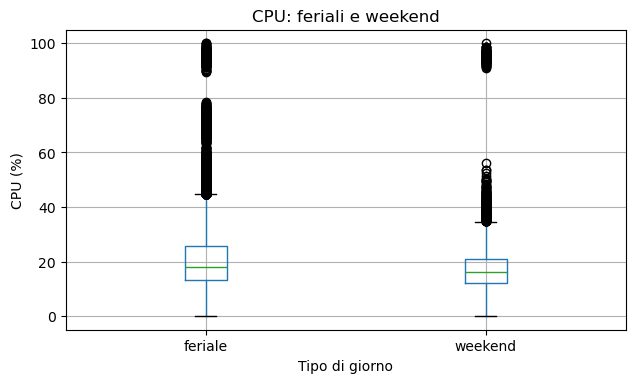

Righe nella finestra di deploy: 400


cpu_pct        ram_pct       
          mean median    mean median
host                                
app-01    71.3   71.4    62.5   62.4
app-02    70.0   70.2    60.7   60.8

CPU media prima, durante e dopo il deploy:


fase,deploy,dopo,prima
host,,,
app-01,71.3,38.4,32.9
app-02,70.0,37.9,32.1


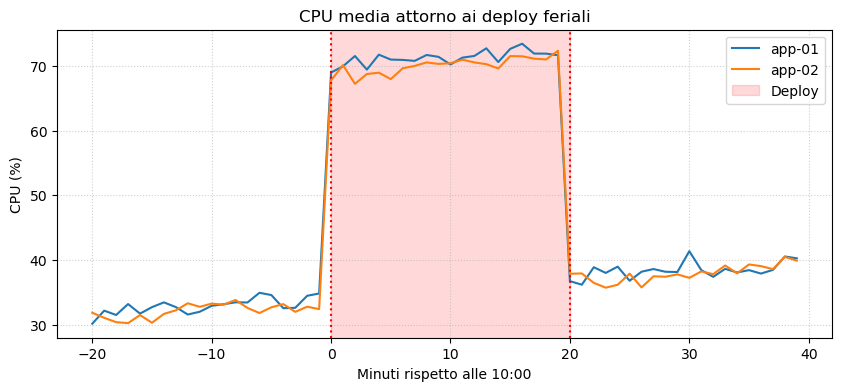

In [201]:
# 1. Grafico di tutti gli episodi dello storico
for _, row in storico.iterrows():
    giorno = row["inizio"].date()
    d_host = telemetria.loc[
        (telemetria["host"] == row["host"])
        & (telemetria["timestamp"].dt.date == giorno)
    ]

    fig, ax = plt.subplots(figsize=(11, 2.5))
    ax.plot(d_host["timestamp"], d_host["cpu_pct"], label="CPU %", color="#0A0AB4", lw=1)
    ax.plot(d_host["timestamp"], d_host["ram_pct"], label="RAM %", color="#E66101", lw=1, linestyle="--")
    ax.axvspan(row["inizio"], row["fine"], color="red", alpha=0.15, label="Finestra episodio")
    ax.set_title(f"Telemetria di {row['host']} il {giorno} ({row['tipo']})")
    ax.set_ylim(0, 105)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right")
    plt.show()

    print(row["note"])
    print("-" * 80)


# 2. Suddivisione giorno/notte e feriali/weekend
ora = telemetria["timestamp"].dt.hour
giorno_settimana = telemetria["timestamp"].dt.dayofweek

dati = telemetria.copy()
dati["fascia"] = np.where((ora >= 8) & (ora < 20), "giorno", "notte")
dati["tipo_giorno"] = np.where(giorno_settimana < 5, "feriale", "weekend")

print("CPU e RAM per fascia oraria:")
display(dati.groupby("fascia")[["cpu_pct", "ram_pct"]].agg(["mean", "median"]).round(1))

print("CPU e RAM per tipo di giorno:")
display(dati.groupby("tipo_giorno")[["cpu_pct", "ram_pct"]].agg(["mean", "median"]).round(1))


# Distribuzione della CPU per fascia oraria
fig, ax = plt.subplots(figsize=(7, 4))
dati.boxplot(column="cpu_pct", by="fascia", ax=ax)
ax.set_title("CPU: giorno e notte")
ax.set_xlabel("Fascia oraria")
ax.set_ylabel("CPU (%)")
plt.suptitle("")
plt.show()

# Distribuzione della CPU per tipo di giorno
fig, ax = plt.subplots(figsize=(7, 4))
dati.boxplot(column="cpu_pct", by="tipo_giorno", ax=ax)
ax.set_title("CPU: feriali e weekend")
ax.set_xlabel("Tipo di giorno")
ax.set_ylabel("CPU (%)")
plt.suptitle("")
plt.show()


# 3. Deploy: app-01/app-02, feriali, dalle 10:00 alle 10:19
minuto_giorno = ora * 60 + telemetria["timestamp"].dt.minute
mask_deploy = (
    telemetria["host"].isin(["app-01", "app-02"])
    & (giorno_settimana < 5)
    & (minuto_giorno >= 600)
    & (minuto_giorno < 620)
)

print(f"Righe nella finestra di deploy: {mask_deploy.sum()}")
display(
    telemetria.loc[mask_deploy]
    .groupby("host")[["cpu_pct", "ram_pct"]]
    .agg(["mean", "median"])
    .round(1)
)

# Confronto prima/durante/dopo il deploy, sugli stessi host e nei giorni feriali
minuti_relativi = minuto_giorno - 600
mask_finestra = (
    telemetria["host"].isin(["app-01", "app-02"])
    & (giorno_settimana < 5)
    & (minuti_relativi >= -20)
    & (minuti_relativi < 40)
)

confronto = telemetria.loc[mask_finestra, ["timestamp", "host", "cpu_pct"]].copy()
confronto["minuto_relativo"] = minuti_relativi.loc[mask_finestra].to_numpy()
confronto["fase"] = np.select(
    [
        confronto["minuto_relativo"] < 0,
        confronto["minuto_relativo"] < 20,
    ],
    ["prima", "deploy"],
    default="dopo",
)

print("CPU media prima, durante e dopo il deploy:")
display(confronto.groupby(["host", "fase"])["cpu_pct"].mean().unstack().round(1))

# Profilo medio minuto per minuto: evidenzia la finestra 10:00–10:19
fig, ax = plt.subplots(figsize=(10, 4))
for host, gruppo in confronto.groupby("host"):
    profilo = gruppo.groupby("minuto_relativo")["cpu_pct"].mean()
    ax.plot(profilo.index, profilo.values, label=host)

ax.axvspan(0, 20, color="red", alpha=0.15, label="Deploy")
ax.axvline(0, color="red", linestyle=":")
ax.axvline(20, color="red", linestyle=":")
ax.set_title("CPU media attorno ai deploy feriali")
ax.set_xlabel("Minuti rispetto alle 10:00")
ax.set_ylabel("CPU (%)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.show()

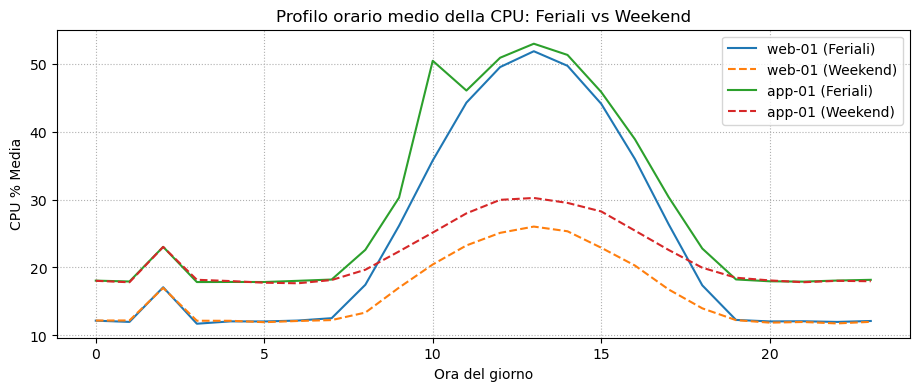

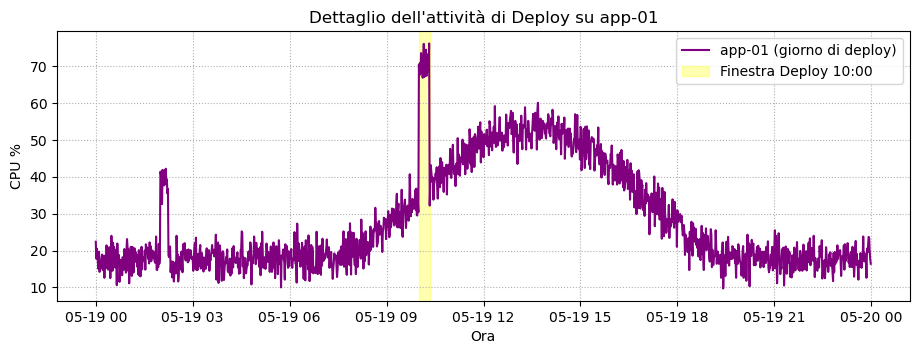

In [202]:
# 1. Analisi feriali vs. weekend
telemetria['is_weekend'] = telemetria['timestamp'].dt.dayofweek >= 5
telemetria['ora'] = telemetria['timestamp'].dt.hour + telemetria['timestamp'].dt.minute / 60


plt.figure(figsize=(11, 4))
for host in ['web-01', 'app-01']:
    feriali = telemetria[(telemetria['host'] == host) & (~telemetria['is_weekend'])].groupby(telemetria['timestamp'].dt.hour)['cpu_pct'].mean()
    weekend = telemetria[(telemetria['host'] == host) & (telemetria['is_weekend'])].groupby(telemetria['timestamp'].dt.hour)['cpu_pct'].mean()
    plt.plot(feriali.index, feriali.values, label=f"{host} (Feriali)", lw=1.5)
    plt.plot(weekend.index, weekend.values, label=f"{host} (Weekend)", lw=1.5, linestyle="--")


plt.title("Profilo orario medio della CPU: Feriali vs Weekend")
plt.xlabel("Ora del giorno")
plt.ylabel("CPU % Media")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()


# 2. Focus sui deploy delle 10:00 (alle 10:00 / minuto 600 di ogni giorno feriale su app-01 e app-02)
plt.figure(figsize=(11, 3.5))
giorno_deploy = telemetria[(telemetria['host'] == 'app-01') & (telemetria['timestamp'].dt.date == pd.Timestamp('2025-05-19').date())]
plt.plot(giorno_deploy['timestamp'], giorno_deploy['cpu_pct'], label="app-01 (giorno di deploy)", color="purple")
plt.axvspan(pd.Timestamp('2025-05-19 10:00'), pd.Timestamp('2025-05-19 10:20'), color='yellow', alpha=0.3, label='Finestra Deploy 10:00')
plt.title("Dettaglio dell'attività di Deploy su app-01")
plt.xlabel("Ora")
plt.ylabel("CPU %")
plt.legend()
plt.grid(True, linestyle=":")
plt.show()





---
## 2 · Modello 1 · Detector di anomalie

Il detector è una **classe** con due metodi:
- `fit(df)`: impara dai dati del kit;
- `score(df)`: restituisce un array di punteggi, **uno per riga di `df`, nello stesso ordine**. Più alto = più anomalo.

`df` ha sempre le colonne `timestamp`, `host`, `cpu_pct`, `ram_pct`. Le feature vanno calcolate **dentro** la classe:
il docente le passerà solo la telemetria grezza dell'incidente.

La versione di partenza qui sotto funziona già. Il vostro compito è **migliorarla**.

In [203]:
class Detector:
    """z-score robusto per (host, feriale/weekend, fascia 10 min) + finestre mobili per host + Isolation Forest.
    Le finestre mobili catturano due cose che il solo z istantaneo non vede:
    - deriva persistente a bassa intensita' (miner notturno al 40%): z_m15, z_m60
    - picchi ricorrenti (beaconing): z_max15 resta alto tra un picco e l'altro
    """
 
    def _fascia(self, df):
        ts = pd.to_datetime(df["timestamp"])
        weekend = (ts.dt.dayofweek >= 5).astype(int)
        fascia = (ts.dt.hour * 60 + ts.dt.minute) // 10
        return df["host"].astype(str) + "|" + weekend.astype(str) + "|" + fascia.astype(str)
 
    def _z(self, df):
        f = self._fascia(df)
        normale = f.map(self.normale).fillna(df["host"].map(self.normale_host))
        scala = np.maximum(1.4826 * f.map(self.variabilita).fillna(0), 2.0)
        return (df["cpu_pct"] - normale) / scala
 
    def features(self, df):
        d = df[["timestamp", "host"]].copy()
        d["z"] = self._z(df).values
        d["_i"] = np.arange(len(d))                       # per ripristinare l'ordine originale
        d = d.sort_values(["host", "timestamp"])
        g = d.groupby("host")["z"]
        d["z_m5"] = g.transform(lambda x: x.rolling(5, min_periods=1).mean())
        d["z_m15"] = g.transform(lambda x: x.rolling(15, min_periods=1).mean())
        d["z_m60"] = g.transform(lambda x: x.rolling(60, min_periods=1).mean())
        d["z_max15"] = g.transform(lambda x: x.rolling(15, min_periods=1).max())
        d = d.sort_values("_i")
        return d[["z", "z_m5", "z_m15", "z_m60", "z_max15"]].reset_index(drop=True)
 
    def fit(self, df):
        f = self._fascia(df)
        cpu = df["cpu_pct"]
        self.normale = cpu.groupby(f).median()
        self.variabilita = (cpu - f.map(self.normale)).abs().groupby(f).median()
        self.normale_host = cpu.groupby(df["host"]).median()
        self.modello = IsolationForest(n_estimators=200, max_samples=16384, random_state=0)
        self.modello.fit(self.features(df))
        return self
 
    def score(self, df):
        return -self.modello.score_samples(self.features(df))

**Idee per migliorare** (scegliete voi):
- feature che confrontino il valore con il **normale di quell'host a quell'ora** (il 40% di CPU non significa la stessa cosa alle 15 e alle 3);
- medie e deviazioni mobili, per host;
- altri modelli visti nel corso: One-Class SVM, autoencoder, ensemble.

In [204]:
detector = Detector().fit(telemetria)
punteggi_kit = detector.score(telemetria)
print("Punteggi calcolati:", len(punteggi_kit))

Punteggi calcolati: 161280


### 2.1 · Autoverifica sugli episodi passati

`simula_su_kit` applica **le stesse regole del docente** ai dati del kit: allarmi raggruppati, coda di 30 allarmi al giorno,
ritardo di rilevamento di ogni episodio dello storico. Usatela per scegliere la soglia.

In [205]:
def simula_su_kit(detector, soglia, punteggi=None):
    s = detector.score(telemetria) if punteggi is None else punteggi
    minuti, allarmi = allarmi_visti(telemetria, s, soglia)
    righe = []
    for _, e in storico.iterrows():
        rit = primo_rilevamento(minuti, e["host"], e["inizio"], e["fine"]) if len(minuti) else None
        righe.append({"host": e["host"], "inizio": e["inizio"], "tipo": e["tipo"],
                      "rilevato_dopo_min": rit, "esito": "entro 15'" if rit is not None and rit <= 15 else
                      ("entro 2h" if rit is not None and rit <= 120 else "mancato")})
    per_giorno = allarmi.groupby("giorno").size() if len(allarmi) else pd.Series(dtype=int)
    print(f"Allarmi al giorno: media {per_giorno.mean():.1f}, massimo {per_giorno.max() if len(per_giorno) else 0} "
          f"(budget {BUDGET_ALLARMI}) · giorni oltre budget: {(per_giorno > BUDGET_ALLARMI).sum()}")
    return pd.DataFrame(righe)

In [206]:
# TODO: scegliete la soglia. Quella di partenza segnala il 5% dei minuti come anomalo.
m = telemetria["timestamp"].dt.hour * 60 + telemetria["timestamp"].dt.minute
deploy = (telemetria["host"].isin(["app-01", "app-02"]) & (telemetria["timestamp"].dt.dayofweek < 5)
          & (m >= 600) & (m < 620))
 
SOGLIA = None
for q in [0.990, 0.992, 0.994, 0.995, 0.996, 0.998, 0.999]:       # dal piu' sensibile al piu' severo
    th = float(np.quantile(punteggi_kit, q))
    minuti, allarmi = allarmi_visti(telemetria, punteggi_kit, th)
    max_giorno = allarmi.groupby("giorno").size().max()
    deploy_flag = minuti[minuti["visto"]].merge(
        telemetria.loc[deploy, ["timestamp", "host"]], on=["timestamp", "host"]).shape[0]
    print(f"q={q}: soglia={th:.3f} max allarmi/giorno={max_giorno} minuti di deploy in allarme={deploy_flag}")
    if max_giorno <= 20 and deploy_flag == 0 and SOGLIA is None:
        SOGLIA = th
 
print("SOGLIA scelta:", SOGLIA)
simula_su_kit(detector, SOGLIA, punteggi_kit)

q=0.99: soglia=0.499 max allarmi/giorno=48 minuti di deploy in allarme=0
q=0.992: soglia=0.529 max allarmi/giorno=22 minuti di deploy in allarme=0
q=0.994: soglia=0.585 max allarmi/giorno=9 minuti di deploy in allarme=0
q=0.995: soglia=0.619 max allarmi/giorno=13 minuti di deploy in allarme=0
q=0.996: soglia=0.675 max allarmi/giorno=15 minuti di deploy in allarme=0
q=0.998: soglia=0.721 max allarmi/giorno=6 minuti di deploy in allarme=0
q=0.999: soglia=0.740 max allarmi/giorno=5 minuti di deploy in allarme=0
SOGLIA scelta: 0.5851734288336975
Allarmi al giorno: media 4.1, massimo 9 (budget 30) · giorni oltre budget: 0


,host,inizio,tipo,rilevato_dopo_min,esito
0,app-02,2025-05-21 14:00:00,miner,0.0,entro 15'
1,web-02,2025-05-25 11:00:00,miner,0.0,entro 15'
2,db-01,2025-05-29 15:00:00,miner,0.0,entro 15'
3,test-01,2025-05-27 02:30:00,miner,0.0,entro 15'
4,mon-01,2025-05-23 14:00:00,beaconing,0.0,entro 15'
5,web-02,2025-05-31 09:00:00,beaconing,0.0,entro 15'


---
## 3 · Modello 2 · Piano di patch

Una **funzione** `piano(report, inventario)` che restituisce la **lista ordinata delle azioni** (valori della colonna `azione` del report).
Il docente le applicherà in quell'ordine finché bastano le 20 ore: la prima azione che non ci sta ferma il piano.

La versione di partenza usa la formula del corso: rischio = CVSS × EPSS × criticità.

In [207]:
def piano_baseline(report, inventario):
    """Versione di partenza: somma di CVSS × EPSS × criticità per azione, in ordine decrescente."""
    r = report.merge(inventario[["asset", "criticita"]], on="asset")
    r["rischio"] = r["cvss"] * r["epss"] * r["criticita"]
    return r.groupby("azione")["rischio"].sum().sort_values(ascending=False).index.tolist()

**Suggerimento:** lo `storico_vuln` dice quali vulnerabilità sono state davvero sfruttate. Quali caratteristiche contano di più?

In [208]:
print(storico_vuln.groupby("esposto_internet")["sfruttata"].mean().round(3))
storico_vuln.groupby(pd.cut(storico_vuln["epss"], [0, 0.05, 0.2, 1]), observed=True)["sfruttata"].mean().round(3)

esposto_internet
False    0.026
True     0.315
Name: sfruttata, dtype: float64


epss
(0.0, 0.05]    0.054
(0.05, 0.2]    0.075
(0.2, 1.0]     0.153
Name: sfruttata, dtype: float64

In [209]:
# Soluzione di riferimento: un modello impara dallo storico la probabilità di sfruttamento,
# poi si ordina per rischio atteso per ora di lavoro.
colonne = ["cvss", "epss", "criticita", "esposto_internet"]
modello_sfruttamento = LogisticRegression(max_iter=1000).fit(storico_vuln[colonne].astype(float), storico_vuln["sfruttata"])
print(dict(zip(colonne, modello_sfruttamento.coef_[0].round(2))))

def piano(report, inventario):
    r = report.merge(inventario[["asset", "criticita", "esposto_internet"]], on="asset")
    r["p_sfruttamento"] = modello_sfruttamento.predict_proba(r[colonne].astype(float))[:, 1]
    r["rischio_atteso"] = r["p_sfruttamento"] * r["criticita"]
    g = r.groupby("azione").agg(rischio=("rischio_atteso", "sum"), ore=("ore_azione", "first"))
    g["rendimento"] = g["rischio"] / g["ore"]
    return g.sort_values("rendimento", ascending=False).index.tolist()

{'cvss': np.float64(-0.12), 'epss': np.float64(1.94), 'criticita': np.float64(-0.08), 'esposto_internet': np.float64(2.63)}


In [210]:
def applica_piano(azioni, report=report, budget=BUDGET_ORE):
    ore_per_azione = report.groupby("azione")["ore_azione"].first()
    ore, applicate = 0, []
    for a in azioni:
        if a not in ore_per_azione:
            continue
        if ore + ore_per_azione[a] > budget:
            break
        ore += ore_per_azione[a]
        applicate.append(a)
    return applicate, ore

mio_piano = piano(report, INVENTARIO)
applicate, ore = applica_piano(mio_piano)
print(f"Azioni applicate entro {BUDGET_ORE} ore ({ore} ore usate):")
print("\n".join("  " + a for a in applicate))

Azioni applicate entro 20 ore (17 ore usate):
  UPGRADE · jquery · 3.5.0
  UPGRADE · nginx · 1.24.0
  UPGRADE · webapp-cms · 4.2.9
  UPGRADE · openssh · 9.6p1
  UPGRADE · log4j-core · 2.17.1


---
## 4 · La nota per il docente

Spiegate in poche righe **come avete scelto la soglia** e **con quale criterio avete ordinato le patch**. Vale 10 punti.

In [211]:
SQUADRA = "BELLOMO_DIFRANCESCANGELO_SAVOV"          # TODO: il nome della vostra squadra, senza spazi
NOTA = """Il detector confronta la CPU di ogni host con il suo "normale" nella stessa fascia di 10 minuti
(feriale/weekend), usando mediana e MAD per essere robusto agli episodi anomali presenti nel kit.
Il modello e' un Isolation Forest su queste feature.
Abbiamo scelto la soglia 0.5852 guardando il compromesso sul kit: massimo 9 allarmi al giorno (media 4.1)
contro un budget di 30, nessun minuto dei deploy delle 10:00 in allarme e tutti e 6 gli episodi storici
rilevati entro pochi minuti. Non abbiamo alzato la soglia per lasciare margine di sensibilita' su un
incidente diverso da quelli visti. Limite: addestramento e soglia sono scelti sullo stesso kit."""

---
## 5 · Esporta la consegna

Il file contiene i **pesi dei modelli** (il detector addestrato), la soglia, la funzione di piano e la nota.
Viene salvato con `cloudpickle`, che include anche il codice delle vostre classi e funzioni: il docente può importarlo senza avere il vostro notebook.

In [212]:
def esporta_consegna(squadra, detector, soglia, piano, nota):
    consegna = {"squadra": squadra, "detector": detector, "soglia": float(soglia), "piano": piano, "nota": nota}
    nome = f"consegna_{squadra}.pkl"
    with open(nome, "wb") as f:
        cloudpickle.dump(consegna, f)
    print("Salvato:", nome)
    return nome

file_consegna = esporta_consegna(SQUADRA, detector, SOGLIA, piano, NOTA)

Salvato: consegna_BELLOMO_DIFRANCESCANGELO_SAVOV.pkl


### 5.1 · Autoverifica della consegna

Ricarichiamo il file come farà il docente e lo facciamo girare sugli ultimi 2 giorni del kit: se questa cella funziona, funzionerà anche da lui.

In [213]:
import time
with open(file_consegna, "rb") as f:
    c = cloudpickle.load(f)
assert set(c) >= {"squadra", "detector", "soglia", "piano", "nota"}, "Mancano dei campi"

prova = telemetria[telemetria["timestamp"] >= telemetria["timestamp"].max() - pd.Timedelta(days=2)].reset_index(drop=True)
t0 = time.time()
s = np.asarray(c["detector"].score(prova))
assert s.shape == (len(prova),), "score() deve restituire un valore per ogni riga, nello stesso ordine"
assert np.isfinite(s).all(), "Ci sono punteggi non validi (NaN o infiniti)"
az = c["piano"](report, INVENTARIO)
assert isinstance(az, list) and all(a in set(report["azione"]) for a in az), "piano() deve restituire azioni del report"
print(f"OK · squadra {c['squadra']} · score in {time.time() - t0:.1f} s · soglia {c['soglia']:.4f} · {len(az)} azioni nel piano")

OK · squadra BELLOMO_DIFRANCESCANGELO_SAVOV · score in 0.5 s · soglia 0.5852 · 10 azioni nel piano
